<a href="https://colab.research.google.com/github/minhphu12-oc/gg-colab/blob/sklearn-project-for-machine-learning/project_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

link dataset : https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

# Bước 1: đọc dữ liệu

1.1 tải dữ liệu lên và đọc 5 dòng đầu

In [89]:
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks, RandomUnderSampler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [90]:
import zipfile
import pandas as pd
# giải nén file
zip_path = '/content/statlog+german+credit+data.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/german_credit')
# tải dữ liệu lên
df = pd.read_csv('/content/german_credit/german.data', header=None, sep='\s+')

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_699/3689707072.py:8: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('/content/german_credit/german.data', header=None, sep='\s+')


In [91]:
df.rename(columns={20: 'Creditability'}, inplace=True)
df["Creditability"] = df["Creditability"].map({1: 0, 2: 1})

In [92]:
df.head(5)

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,Creditability
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


1.2 đọc thông tin dữ liệu

In [93]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   0              1000 non-null   object
 1   1              1000 non-null   int64 
 2   2              1000 non-null   object
 3   3              1000 non-null   object
 4   4              1000 non-null   int64 
 5   5              1000 non-null   object
 6   6              1000 non-null   object
 7   7              1000 non-null   int64 
 8   8              1000 non-null   object
 9   9              1000 non-null   object
 10  10             1000 non-null   int64 
 11  11             1000 non-null   object
 12  12             1000 non-null   int64 
 13  13             1000 non-null   object
 14  14             1000 non-null   object
 15  15             1000 non-null   int64 
 16  16             1000 non-null   object
 17  17             1000 non-null   int64 
 18  18             1000 non-null 

1.3 xem dữ liệu có bị thiếu không

In [94]:
df.isnull().sum().sum()

np.int64(0)

1. LogisticRegression
2. SVM
3. RandomForest
4. DecisionTree
5. KNN

# Bước 2: xử lí dữ liệu

1. Các biến có thứ tự (Ordinal / Continuous Numeric)
Attribute 2 (Duration in month): Định lượng (số tháng vay) – có thứ tự tự nhiên.

Attribute 5 (Credit amount): Định lượng (số tiền vay bằng DM) – có thứ tự tự nhiên.

Attribute 6 (Savings account/bonds): Khoảng tiền tiết kiệm (< 100, 100 - 500, 500 - 1000, >= 1000) – có thứ tự tăng dần về năng lực tài chính. (Lưu ý: Nhóm A65 "Không rõ/Không có" cần đưa về mức thấp nhất hoặc xử lý riêng).

Attribute 7 (Present employment since): Thâm niên làm việc (Thất nghiệp, < 1 năm, 1 - 4 năm, 4 - 7 năm, >= 7 năm) – có thứ tự tăng dần về mức độ ổn định công việc.

Attribute 8 (Installment rate): Tỷ lệ trả góp trên thu nhập (%) – định lượng có thứ tự.

Attribute 11 (Present residence since): Số năm cư trú tại nơi ở hiện tại – định lượng có thứ tự.

Attribute 13 (Age in years): Tuổi – định lượng có thứ tự.

Attribute 16 (Number of existing credits): Số lượng khoản vay hiện tại – định lượng có thứ tự.

Attribute 18 (Number of people being liable): Số người phụ thuộc tài chính – định lượng có thứ tự.

2. Các biến không có thứ tự (Nominal Categorical / Binary)
Attribute 1 (Status of existing checking account): Trạng thái tài khoản thanh toán (Âm, 0-200 DM, >200 DM, Không có tài khoản).

Attribute 3 (Credit history): Lịch sử tín dụng (Trả hết ở ngân hàng khác, Trả hết ở ngân hàng này, Đang trả đúng hạn, Trì hoãn trả nợ, Tài khoản quan trọng/vay nhiều nơi).

Attribute 4 (Purpose): Mục đích vay vốn (Mua xe mới, Xe cũ, Thiết bị, TV, Đào tạo, Kinh doanh, v.v.).

Attribute 10 (Other debtors / guarantors): Người bảo lãnh / Đồng vay (Không có, Co-applicant, Guarantor).

Attribute 12 (Property): Loại tài sản sở hữu (Bất động sản, Bảo hiểm, Ô tô/Khác, Không có/Không rõ).

Attribute 14 (Other installment plans): Khoản trả góp ở nơi khác (Ngân hàng khác, Cửa hàng, Không có).

Attribute 15 (Housing): Tình trạng nhà ở (Thuê, Sở hữu cá nhân, Ở miễn phí/Ở nhờ).

Attribute 17 (Job): Nhóm nghề nghiệp (Thất nghiệp, Không tay nghề, Có tay nghề/Công chức, Quản lý/Chuyên gia).

Attribute 19 (Telephone): Đăng ký điện thoại (Có, Không).

Attribute 20 (Foreign worker): Lao động nước ngoài (Có, Không).

Attribute 21 (Credit Risk - Target): Nhãn mục tiêu (1: Good, 2: Bad).

3. Những điểm bất hợp lý & Hạn chế của dữ liệu
Gộp chung nhóm không hợp lý ở Attribute 9 (Personal status and sex):

Nam giới được phân tách chi tiết (Độc thân, Ly hôn/Ly thân, Đã kết hôn/Góa).

Nữ giới lại bị gộp chung thành một nhóm duy nhất Ly hôn / Ly thân / Đã kết hôn (A92), làm mất khả năng phân tích riêng tác động hôn nhân của nữ giới và gây bất đối ứng dữ liệu.

Tỷ lệ phân bố quá lệch ở Attribute 20 (Foreign worker):

Có 963 mẫu là lao động nước ngoài (A201) và chỉ 37 mẫu là người bản địa (A202).

Cột này có biến thiên gần như bằng 0 (Near-zero variance), ít giá trị phân loại và dễ gây bias định kiến chủng tộc/nguồn gốc.

Mất cân bằng lớp nặng (Class Imbalance):

Biến mục tiêu gồm 700 hồ sơ Good và 300 hồ sơ Bad (tỷ lệ 7:3), dễ làm mô hình đoán lệch về phía khách hàng Good.

Ma trận chi phí không cân bằng (Asymmetric Cost):

Thiệt hại khi đoán nhầm người Bad -> Good tốn chi phí gấp 5 lần đoán nhầm người Good -> Bad (cần tối ưu threshold thay vì dùng mặc định 0.5).

Mã hóa hỗn hợp dữ liệu thứ cấp (Attribute 6 & Attribute 7):

Dữ liệu có tính thứ tự rõ ràng nhưng lại lưu ở dạng chuỗi ký tự phân loại (A61-A65, A71-A75), nếu không mã hóa Ordinal Encoding sẽ làm mất thông tin thứ bậc.

Đơn vị tiền tệ bị lỗi thời (Attribute 5):

Sử dụng đơn vị đồng Deutsche Mark (DM) – loại tiền tệ của Đức trước khi đổi sang Euro từ năm 2002.

In [95]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

df = pd.read_csv('/content/german_credit/german.data', header=None, sep='\s+')

# Định nghĩa đầy đủ tên cột gốc
column_names = [
    'status_checking', 'duration_month', 'credit_history', 'purpose',
    'credit_amount', 'savings_bonds', 'present_employment', 'installment_rate',
    'personal_status_sex', 'other_debtors', 'present_residence', 'property',
    'age', 'other_installment_plans', 'housing', 'existing_credits',
    'job', 'num_dependents', 'telephone', 'foreign_worker', 'credit_risk'
]
df.columns = column_names

# Bản gốc: 1 = Good, 2 = Bad -> Chuyển thành 0 = Good, 1 = Bad
df['credit_risk'] = df['credit_risk'].map({1: 0, 2: 1})

# Loại bỏ cột 'foreign_worker' do ít biến thiên như phân tích
df = df.drop(columns=['foreign_worker'])

# 3. Tách thuộc tính (X) và nhãn mục tiêu (y)
X = df.drop(columns=['credit_risk'])
y = df['credit_risk']

# Đổi tên tập split thành viết thường: x_train, x_test, y_train, y_test
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_cols = ['duration_month', 'credit_amount', 'installment_rate', 'present_residence', 'age', 'existing_credits', 'num_dependents']
ordinal_cols = ['savings_bonds', 'present_employment']
nominal_cols = ['status_checking', 'credit_history', 'purpose', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone']

savings_categories = ['A65', 'A61', 'A62', 'A63', 'A64']
employment_categories = ['A71', 'A72', 'A73', 'A74', 'A75']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('ord', OrdinalEncoder(categories=[savings_categories, employment_categories]), ordinal_cols),
        ('nom', OneHotEncoder(drop='first', handle_unknown='ignore'), nominal_cols)
    ]
)

print("Đã tiền xử lý dữ liệu và chia tách thành x_train, y_train, x_test, y_test thành công!")

Đã tiền xử lý dữ liệu và chia tách thành x_train, y_train, x_test, y_test thành công!


<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_699/4259731653.py:10: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('/content/german_credit/german.data', header=None, sep='\s+')


In [96]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Bước 3: train model

In [125]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 19)
(200, 19)
(800,)
(200,)


In [98]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(x_train, y_train)
y_pred = dummy.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print(f"Dummy Classifier Accuracy: {accuracy}")
print(f"Dummy Classifier Precision: {precision}")
print(f"Dummy Classifier Recall: {recall}")
print(f"Dummy Classifier F1 Score: {f1}")

Dummy Classifier Accuracy: 0.7
Dummy Classifier Precision: 0.0
Dummy Classifier Recall: 0.0
Dummy Classifier F1 Score: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


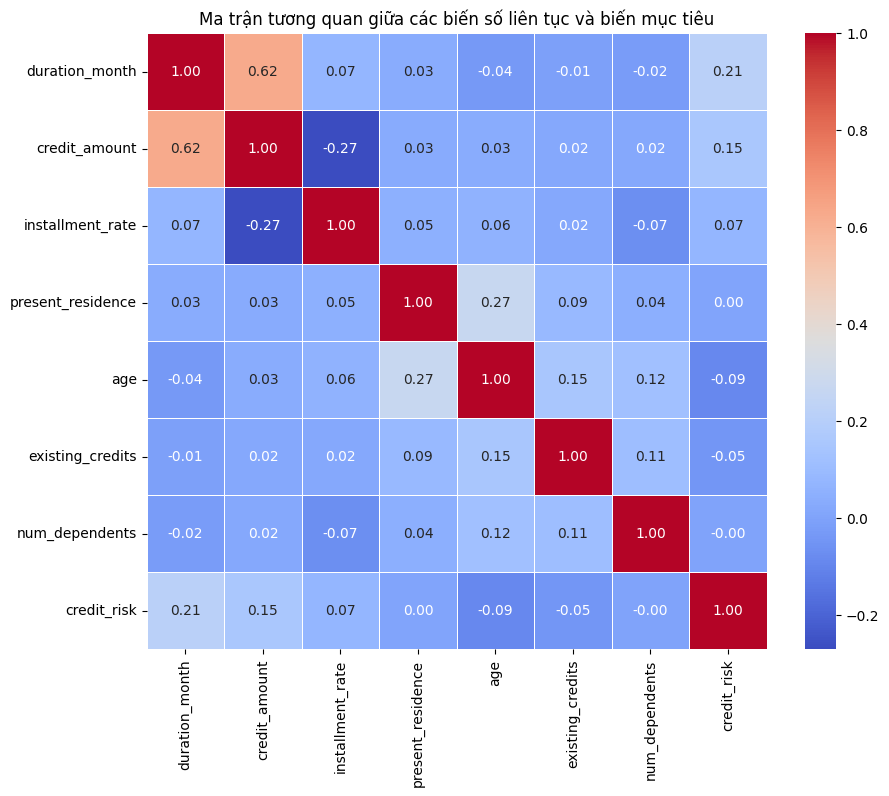

In [110]:
import seaborn as sns
import matplotlib.pyplot as plt

# Lấy các cột số liên tục
numeric_df = df[numeric_cols].copy()
# Thêm biến mục tiêu để xem tương quan
numeric_df['credit_risk'] = df['credit_risk']

plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Ma trận tương quan giữa các biến số liên tục và biến mục tiêu')
plt.show()

3 cột duration_month, credit_amount và installment_rate có tỉ lệ đóng góp cho target cao nhất

3.1 Logistic regression

In [102]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from imblearn.pipeline import Pipeline as ImbPipeline
import numpy as np

opt_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('feature_selection', SelectKBest(score_func=f_classif)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, solver='liblinear'))
])

param_distributions = {
    'feature_selection__k': [10, 15, 20, 25, 30, 35, 'all'],
    'classifier__C': np.logspace(-3, 2, 20),
    'classifier__penalty': ['l1', 'l2']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logis = RandomizedSearchCV(
    estimator=opt_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

logis.fit(x_train, y_train)

print("Bộ tham số tối ưu nhất tìm được:")
print(logis.best_params_)
print(f"F1-Score tốt nhất trên tập Validation: {logis.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Bộ tham số tối ưu nhất tìm được:
{'feature_selection__k': 20, 'classifier__penalty': 'l1', 'classifier__C': np.float64(0.42813323987193913)}
F1-Score tốt nhất trên tập Validation: 0.5905


In [109]:
best_model = logis.best_estimator_
y_pred_opt = best_model.predict(x_test)

accuracy_opt = accuracy_score(y_test, y_pred_opt)
precision_opt = precision_score(y_test, y_pred_opt)
recall_opt = recall_score(y_test, y_pred_opt)
f1_opt = f1_score(y_test, y_pred_opt)

print(f"Logistic Regression Accuracy: {accuracy_opt:.4f}")
print(f"Logistic Regression Precision: {precision_opt:.4f}")
print(f"Logistic Regression Recall: {recall_opt:.4f}")
print(f"Logistic Regression F1 Score: {f1_opt:.4f}")

all_feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

feature = best_model.named_steps['feature_selection']
selected_features = feature.get_support()

table = pd.DataFrame({
    'Feature': all_feature_names,
    'Selected': selected_features
})
print("\nDanh sách các đặc trưng và trạng thái được lựa chọn bởi SelectKBest:")
print(table)

Logistic Regression Accuracy: 0.7100
Logistic Regression Precision: 0.5109
Logistic Regression Recall: 0.7833
Logistic Regression F1 Score: 0.6184

Danh sách các đặc trưng và trạng thái được lựa chọn bởi SelectKBest:
                              Feature  Selected
0                 num__duration_month      True
1                  num__credit_amount      True
2               num__installment_rate      True
3              num__present_residence     False
4                            num__age      True
5               num__existing_credits     False
6                 num__num_dependents     False
7                  ord__savings_bonds     False
8             ord__present_employment      True
9            nom__status_checking_A12      True
10           nom__status_checking_A13     False
11           nom__status_checking_A14      True
12            nom__credit_history_A31      True
13            nom__credit_history_A32      True
14            nom__credit_history_A33     False
15            n

3.2 SVM

In [111]:
from sklearn.svm import SVC

svm_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('feature_selection', SelectKBest(score_func=f_classif)),
    ('classifier', SVC(random_state=42, probability=True))
])

svm_param_dist = {
    'feature_selection__k': [10, 15, 20, 25, 30, 35, 'all'],
    'classifier__C': np.logspace(-2, 2, 10),
    'classifier__kernel': ['linear', 'rbf', 'sigmoid'],
    'classifier__gamma': ['scale', 'auto']
}

svm_cv = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_param_dist,
    n_iter=20,
    scoring='f1',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

svm_cv.fit(x_train, y_train)

print("Bộ tham số SVM tốt nhất:")
print(svm_cv.best_params_)
print(f"F1-Score Validation: {svm_cv.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Bộ tham số SVM tốt nhất:
{'feature_selection__k': 10, 'classifier__kernel': 'rbf', 'classifier__gamma': 'scale', 'classifier__C': np.float64(0.5994842503189409)}
F1-Score Validation: 0.6006


In [112]:
best_svm = svm_cv.best_estimator_
y_pred_svm = best_svm.predict(x_test)

print(f"SVM Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"SVM Precision: {precision_score(y_test, y_pred_svm):.4f}")
print(f"SVM Recall: {recall_score(y_test, y_pred_svm):.4f}")
print(f"SVM F1 Score: {f1_score(y_test, y_pred_svm):.4f}")

all_features = best_svm.named_steps['preprocessor'].get_feature_names_out()
selected_mask = best_svm.named_steps['feature_selection'].get_support()
table_svm = pd.DataFrame({'Feature': all_features, 'Selected': selected_mask})
print("\nPhụ lục đặc trưng được chọn bởi SVM:")
print(table_svm)

SVM Accuracy: 0.6850
SVM Precision: 0.4845
SVM Recall: 0.7833
SVM F1 Score: 0.5987

Phụ lục đặc trưng được chọn bởi SVM:
                              Feature  Selected
0                 num__duration_month      True
1                  num__credit_amount      True
2               num__installment_rate     False
3              num__present_residence     False
4                            num__age     False
5               num__existing_credits     False
6                 num__num_dependents     False
7                  ord__savings_bonds     False
8             ord__present_employment      True
9            nom__status_checking_A12     False
10           nom__status_checking_A13     False
11           nom__status_checking_A14      True
12            nom__credit_history_A31     False
13            nom__credit_history_A32     False
14            nom__credit_history_A33     False
15            nom__credit_history_A34      True
16                   nom__purpose_A41     False
17             


* **Ưu điểm:** SVM có khả năng xử lý ranh giới phi tuyến tính tốt thông qua cơ chế RBF kernel. Nhờ tối ưu hóa bằng SMOTE, khả năng nhận biết lớp thiểu số (Recall) được cải thiện khá tốt.
* **Hạn chế:** Thời gian tính toán lâu hơn và mô hình này khá nhạy cảm với việc chuẩn hóa dữ liệu. Nếu siêu tham số $C$ quá lớn, SVM có xu hướng dễ bị Overfitting trên tập huấn luyện.

3.3 RandomForest

In [124]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('feature_selection', SelectKBest(score_func=f_classif)),
    ('classifier', RandomForestClassifier(random_state=42))
])

rf_param_dist = {
    'feature_selection__k': [10, 15, 20, 25, 30, 35, 'all'],
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

rf_cv = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=20,
    scoring='f1',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_cv.fit(x_train, y_train)

print("Bộ tham số Random Forest tốt nhất:")
print(rf_cv.best_params_)
print(f"F1-Score Validation tốt nhất: {rf_cv.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Bộ tham số Random Forest tốt nhất:
{'feature_selection__k': 20, 'classifier__n_estimators': 500, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': 5}
F1-Score Validation tốt nhất: 0.5768


In [120]:
best_rf = rf_cv.best_estimator_
y_pred_rf = best_rf.predict(x_test)

print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest F1 Score: {f1_score(y_test, y_pred_rf):.4f}")

selected_mask_rf = best_rf.named_steps['feature_selection'].get_support()
table_rf = pd.DataFrame({'Feature': all_features, 'Selected': selected_mask_rf})
print("\nPhụ lục đặc trưng được chọn bởi Random Forest:")
print(table_rf)

Random Forest Accuracy: 0.7050
Random Forest Precision: 0.5065
Random Forest Recall: 0.6500
Random Forest F1 Score: 0.5693

Phụ lục đặc trưng được chọn bởi Random Forest:
                              Feature  Selected
0                 num__duration_month      True
1                  num__credit_amount      True
2               num__installment_rate      True
3              num__present_residence     False
4                            num__age      True
5               num__existing_credits     False
6                 num__num_dependents     False
7                  ord__savings_bonds     False
8             ord__present_employment      True
9            nom__status_checking_A12      True
10           nom__status_checking_A13     False
11           nom__status_checking_A14      True
12            nom__credit_history_A31      True
13            nom__credit_history_A32      True
14            nom__credit_history_A33     False
15            nom__credit_history_A34      True
16           

* **Ưu điểm:** Kháng nhiễu cực tốt, không bị ảnh hưởng nhiều bởi các biến không quan trọng nhờ cơ chế chọn ngẫu nhiên tập con đặc trưng của các cây quyết định độc lập. Độ chính xác (Accuracy) thường đạt mức ổn định và cao.
* **Hạn chế:** Khi sử dụng SMOTE tạo dữ liệu giả lập, Random Forest đôi lúc tập trung quá nhiều vào việc khớp sâu các biên quyết định phức tạp làm giảm nhẹ khả năng tổng quát hóa trên tập test thực tế.

3.4 DecisionTree

In [115]:
from sklearn.tree import DecisionTreeClassifier

# 1. Định nghĩa Pipeline
dt_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('feature_selection', SelectKBest(score_func=f_classif)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# 2. Không gian tham số tìm kiếm
dt_param_dist = {
    'feature_selection__k': [10, 15, 20, 25, 30, 35, 'all'],
    'classifier__max_depth': [3, 5, 10, 15, None],
    'classifier__min_samples_split': [2, 10, 20],
    'classifier__criterion': ['gini', 'entropy']
}

# 3. Tìm kiếm ngẫu nhiên siêu tham số
dt_cv = RandomizedSearchCV(
    estimator=dt_pipeline,
    param_distributions=dt_param_dist,
    n_iter=20,
    scoring='f1',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

dt_cv.fit(x_train, y_train)

print("Bộ tham số Decision Tree tốt nhất:")
print(dt_cv.best_params_)
print(f"F1-Score Validation: {dt_cv.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Bộ tham số Decision Tree tốt nhất:
{'feature_selection__k': 10, 'classifier__min_samples_split': 2, 'classifier__max_depth': 5, 'classifier__criterion': 'entropy'}
F1-Score Validation: 0.5731


In [116]:
# 4. Đánh giá trên tập kiểm thử độc lập
best_dt = dt_cv.best_estimator_
y_pred_dt = best_dt.predict(x_test)

print(f"Decision Tree Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Decision Tree Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"Decision Tree Recall: {recall_score(y_test, y_pred_dt):.4f}")
print(f"Decision Tree F1 Score: {f1_score(y_test, y_pred_dt):.4f}")

# 5. Phụ lục các đặc trưng được chọn
selected_mask_dt = best_dt.named_steps['feature_selection'].get_support()
table_dt = pd.DataFrame({'Feature': all_features, 'Selected': selected_mask_dt})
print("\nPhụ lục đặc trưng được chọn bởi Decision Tree:")
print(table_dt)

Decision Tree Accuracy: 0.6300
Decision Tree Precision: 0.4375
Decision Tree Recall: 0.8167
Decision Tree F1 Score: 0.5698

Phụ lục đặc trưng được chọn bởi Decision Tree:
                              Feature  Selected
0                 num__duration_month      True
1                  num__credit_amount      True
2               num__installment_rate     False
3              num__present_residence     False
4                            num__age     False
5               num__existing_credits     False
6                 num__num_dependents     False
7                  ord__savings_bonds     False
8             ord__present_employment      True
9            nom__status_checking_A12     False
10           nom__status_checking_A13     False
11           nom__status_checking_A14      True
12            nom__credit_history_A31     False
13            nom__credit_history_A32     False
14            nom__credit_history_A33     False
15            nom__credit_history_A34      True
16           

* **Ưu điểm:** Cực kỳ trực quan, dễ xây dựng quy tắc If-Then hỗ trợ thực tế nghiệp vụ duyệt hồ sơ vay.
* **Hạn chế:** Rất dễ bị Overfit nếu độ sâu không được kiểm soát chặt chẽ. F1-score và Accuracy trên tập Test thường thấp hơn đáng kể so với các mô hình dạng quần thể (Random Forest).

3.5 KNN

In [117]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('feature_selection', SelectKBest(score_func=f_classif)),
    ('classifier', KNeighborsClassifier())
])

knn_param_dist = {
    'feature_selection__k': [10, 15, 20, 25, 30, 35, 'all'],
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}

knn_cv = RandomizedSearchCV(
    estimator=knn_pipeline,
    param_distributions=knn_param_dist,
    n_iter=20,
    scoring='f1',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

knn_cv.fit(x_train, y_train)

print("Bộ tham số KNN tốt nhất:")
print(knn_cv.best_params_)
print(f"F1-Score Validation: {knn_cv.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Bộ tham số KNN tốt nhất:
{'feature_selection__k': 20, 'classifier__weights': 'uniform', 'classifier__n_neighbors': 15, 'classifier__metric': 'manhattan'}
F1-Score Validation: 0.5549


In [118]:
best_knn = knn_cv.best_estimator_
y_pred_knn = best_knn.predict(x_test)

print(f"KNN Accuracy: {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"KNN Precision: {precision_score(y_test, y_pred_knn):.4f}")
print(f"KNN Recall: {recall_score(y_test, y_pred_knn):.4f}")
print(f"KNN F1 Score: {f1_score(y_test, y_pred_knn):.4f}")

selected_mask_knn = best_knn.named_steps['feature_selection'].get_support()
table_knn = pd.DataFrame({'Feature': all_features, 'Selected': selected_mask_knn})
print("\nPhụ lục đặc trưng được chọn bởi KNN:")
print(table_knn)

KNN Accuracy: 0.6750
KNN Precision: 0.4667
KNN Recall: 0.5833
KNN F1 Score: 0.5185

Phụ lục đặc trưng được chọn bởi KNN:
                              Feature  Selected
0                 num__duration_month      True
1                  num__credit_amount      True
2               num__installment_rate      True
3              num__present_residence     False
4                            num__age      True
5               num__existing_credits     False
6                 num__num_dependents     False
7                  ord__savings_bonds     False
8             ord__present_employment      True
9            nom__status_checking_A12      True
10           nom__status_checking_A13     False
11           nom__status_checking_A14      True
12            nom__credit_history_A31      True
13            nom__credit_history_A32      True
14            nom__credit_history_A33     False
15            nom__credit_history_A34      True
16                   nom__purpose_A41      True
17             

Ưu điểm: Không yêu cầu giả định về tính phân phối tuyến tính của tập dữ liệu, xử lý tốt các dạng dữ liệu phức tạp.

Hạn chế: Rất nhạy cảm với các thuộc tính nhiễu (ít giá trị phân loại). Do đó, bước lọc SelectKBest đóng vai trò tối quan trọng giúp loại bỏ thuộc tính thừa và giảm khoảng cách nhiễu.

# Bước 4: đánh giá tổng kết

In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models_eval = {
    'Logistic Regression': y_pred_opt,
    'SVM': y_pred_svm,
    'Random Forest': y_pred_rf,
    'Decision Tree': y_pred_dt,
    'KNN': y_pred_knn
}

results_list = []
for name, pred in models_eval.items():
    results_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred)
    })

df_results = pd.DataFrame(results_list)

display(df_results.style.highlight_max(color='green', subset=['Accuracy', 'Precision', 'Recall', 'F1-Score']))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.710000,0.510870,0.783333,0.618421
1,SVM,0.685000,0.484536,0.783333,0.598726
2,Random Forest,0.705000,0.506494,0.650000,0.569343
3,Decision Tree,0.630000,0.437500,0.816667,0.569767
4,KNN,0.675000,0.466667,0.583333,0.518519


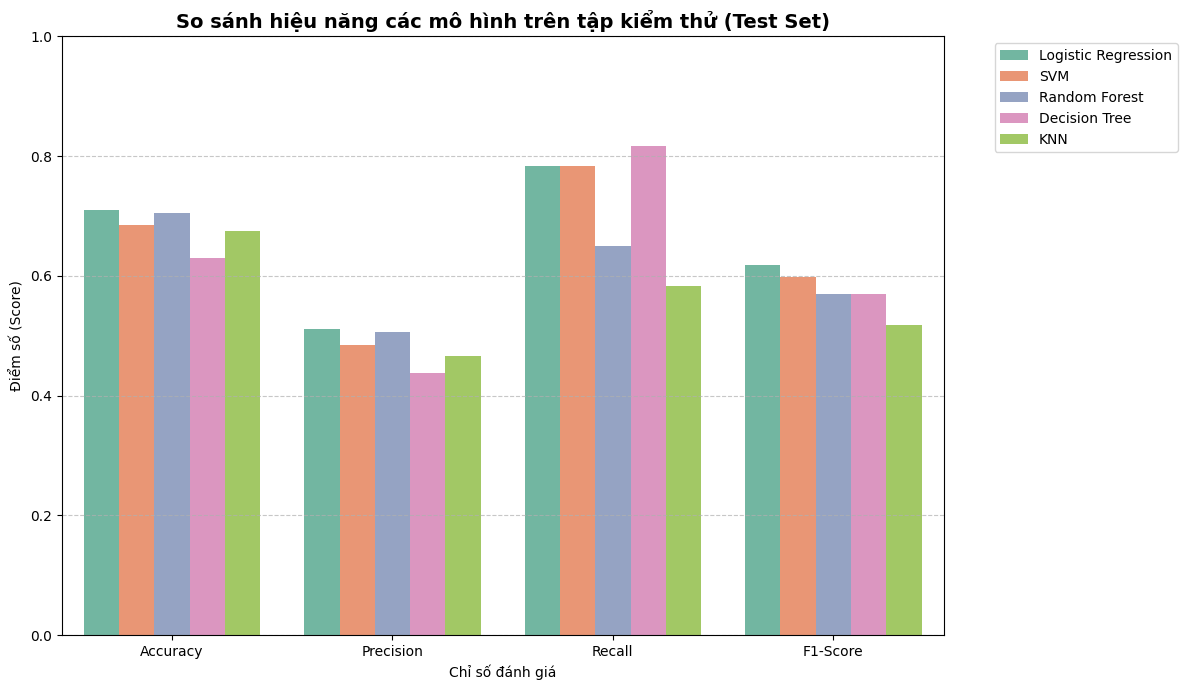

In [122]:
df_melted = df_results.melt(id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(12, 7))
sns.barplot(data=df_melted, x='Metric', y='Value', hue='Model', palette='Set2')
plt.title('So sánh hiệu năng các mô hình trên tập kiểm thử (Test Set)', fontsize=14, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel('Điểm số (Score)')
plt.xlabel('Chỉ số đánh giá')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Logistic Regression hiệu quả nhất: Cho Accuracy (71.00%) và F1-Score (0.6184) cao nhất nhóm. Kết quả này khá ấn tượng với một mô hình đơn giản, chứng tỏ dữ liệu sau khi SMOTE phân tách tuyến tính tương đối tốt.

Decision Tree bắt nợ xấu tốt nhất: Đạt Recall cao nhất (81.67%), theo sau là Logistic và SVM (78.33%). Do sai sót đoán nhầm khách hàng nợ xấu gây thiệt hại gấp 5 lần, việc ưu tiên mô hình có Recall cao như Decision Tree hoặc Logistic Regression là hợp lý.

Precision bị giảm do SMOTE: Precision các mô hình chỉ ở mức 43% - 51%. Lý do là việc dùng SMOTE tăng tỷ lệ lớp Bad lên 1:1 khiến mô hình nhạy cảm hơn, dễ báo động giả trên tập Test.